# M10-2 | The Backend Compiler's View: Checking Whether a Q/DQ Graph Meets the Hardware Constraints

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m10_custom_backend/02_constraint_checker.ipynb)

The `MyVPUQuantizer` of M10-1 promises to produce graphs that satisfy the VPU constraints. But all the backend compiler receives is the Q/DQ graph from `convert_pt2e`; it does not know which quantizer annotated it, and it should not trust it. So the compiler has to check the graph itself before consuming it.

This notebook writes a checker pass `check_vpu` that reads only the Q/DQ graph, with rules corresponding to constraints (2) to (8) of `vpu_quantizer.py`. Constraint (1) (the op list) is not a violation: ops outside the list fall back to CPU, which M10-3 handles.

- **A.** Seven rules: what each looks at on the Q/DQ graph.
- **B.** Two Q/DQ graphs through the check: the one from `MyVPUQuantizer` vs the one from the torchao test-version XNNPACKQuantizer.
- **C.** What passing the check buys: the requant factor of every conv/linear is $2^k$, so the hardware can do it with a shift.

In [ ]:
#| include: false
# On Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# On your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import this course's common/
    os.chdir(f"{repo}/en/m10_custom_backend")

In [1]:
import torch
from torch.fx import Node

from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.data import calibration_batches, trained_tiny_net
from common.models import example_inputs
from common.viz import draw, table
from vpu_quantizer import ADD, CAT, CONV2D, FLATTEN, LINEAR, MAX_POOL2D, RELU, fused_relu, vpu_ptq

quiet()
_ = torch.manual_seed(0)
QD = torch.ops.quantized_decomposed
Q_T, DQ_T, DQ_C = QD.quantize_per_tensor.default, QD.dequantize_per_tensor.default, QD.dequantize_per_channel.default
BATCH = 16

## A. Seven Rules

| Rule | What it checks on the Q/DQ graph | Constraint |
|---|---|---|
| R1 | every `quantize_per_tensor` (activation) is int8 with zero point = 0 | (2) |
| R2 | the scale of every `quantize_per_tensor` and of the weight's dequantize is $2^k$ | (4) |
| R3 | add/cat/max_pool2d/flatten: the input dq and the output q share one scale | (6) |
| R4 | the bias of conv/linear comes from an int32 `dequantize_per_channel`, with scale = $s_{in} \cdot s_w$ | (5) |
| R5 | the input of relu is not "conv/linear/add → q → dq" (no quantization point in between) | (7) |
| R6 | no SymInt in the placeholder shapes | (8) |
| R7 | the weight of conv/linear comes from `dequantize_per_channel`, with all-zero zero points and range [-127, 127] | (3) |

The checker pass reads only the q/dq parameters and the connections, not the annotations (after convert the annotations no longer matter). First two small functions to read scales:

In [2]:
def scale_of(gm, n: Node) -> torch.Tensor:
    """The scale of a q/dq node: per-tensor is a float in args, per-channel is a buffer pointed to by get_attr."""
    s = n.args[1]
    if isinstance(s, Node):
        s = getattr(gm, str(s.target))
    return torch.as_tensor(s, dtype=torch.float64).flatten()


def is_pow2(s: torch.Tensor) -> bool:
    return bool(torch.all(torch.log2(s) == torch.round(torch.log2(s))))


def is_call(n, target) -> bool:
    return isinstance(n, Node) and n.op == "call_function" and n.target == target


def requant_inputs(gm, op: Node):
    """The (s_in, s_w, s_out) of a conv/linear; s_out is taken from the quantize_per_tensor after the output (or the fused relu)."""
    act, weight = op.args[0], op.args[1]
    assert isinstance(act, Node) and isinstance(weight, Node)
    out = fused_relu(op) or op
    q = next((u for u in out.users if is_call(u, Q_T)), None)
    return scale_of(gm, act), scale_of(gm, weight), (scale_of(gm, q) if q is not None else None)

The checker pass itself: walk the nodes of the graph one by one; each rule takes a few lines.

In [3]:
def check_vpu(gm):
    """Read only the Q/DQ graph and return the list of violations [(rule, node name, detail)]."""
    bad = []
    for n in gm.graph.nodes:
        if n.op == "placeholder":                                                     # R6
            val = n.meta.get("val")
            if isinstance(val, torch.Tensor) and not all(isinstance(d, int) for d in val.shape):
                bad.append(("R6", n.name, f"shape {tuple(val.shape)}"))
        if n.op != "call_function":
            continue
        if n.target == Q_T and (n.args[2] != 0 or n.args[5] != torch.int8):         # R1
            bad.append(("R1", n.name, f"zero point = {n.args[2]}"))
        if n.target in (Q_T, DQ_C) and not is_pow2(scale_of(gm, n)):                # R2
            bad.append(("R2", n.name, f"scale = {scale_of(gm, n)[0].item():.5g}"))
        if n.target in (ADD, CAT, MAX_POOL2D, FLATTEN):                               # R3
            ins = n.args[0] if n.target == CAT else (n.args[:2] if n.target == ADD else n.args[:1])
            assert isinstance(ins, (list, tuple))
            out = fused_relu(n) or n
            scales = {float(scale_of(gm, a)) for a in ins if is_call(a, DQ_T)}
            scales |= {float(scale_of(gm, q)) for q in out.users if is_call(q, Q_T)}
            if len(scales) > 1:
                bad.append(("R3", n.name, "scale = " + ", ".join(f"{s:.5g}" for s in sorted(scales))))
        if n.target in (CONV2D, LINEAR) and len(n.args) > 2 and isinstance(b := n.args[2], Node):   # R4
            if not (is_call(b, DQ_C) and b.args[-1] == torch.int32):
                bad.append(("R4", n.name, f"bias comes from {b.op} node {b.name} (fp32)"))
            else:
                s_in, s_w, _ = requant_inputs(gm, n)
                if not torch.equal(scale_of(gm, b), s_in * s_w):
                    bad.append(("R4", n.name, "bias scale != s_in x s_w"))
        if n.target in (CONV2D, LINEAR):
            w, zp = n.args[1], None
            assert isinstance(w, Node)
            if is_call(w, DQ_T) and not is_pow2(scale_of(gm, w)):                     # R2: per-tensor weight
                bad.append(("R2", w.name, f"scale = {scale_of(gm, w)[0].item():.5g}"))
            if is_call(w, DQ_C) and isinstance(z := w.args[2], Node):
                zp = getattr(gm, str(z.target))
            if zp is None:                                                            # R7
                bad.append(("R7", n.name, f"weight comes from {w.op} node {w.name}, not per-channel"))
            elif torch.any(zp != 0) or w.args[4:6] != (-127, 127):
                bad.append(("R7", n.name, f"range {w.args[4:6]}, or zero point is not 0"))
        if n.target == RELU:                                                          # R5
            src = n.args[0]
            if is_call(src, DQ_T) and is_call(q := src.args[0], Q_T) and isinstance(op := q.args[0], Node) \
                    and op.target in (CONV2D, LINEAR, ADD):
                bad.append(("R5", n.name, f"there is a q/dq between {op.name} and relu"))
    return bad

## B. Two Q/DQ Graphs Through the Check

Both graphs come from the trained TinyConvNet and the same calibration data:

- The VPU graph: `vpu_ptq` (`vpu_quantizer.py`) = `torch.export.export(model, x)` (static shape) → `prepare_pt2e(…, MyVPUQuantizer())` → calibrate → `convert_pt2e`.
- The XNNPACK graph: the default of `export_module` (dynamic batch) → `prepare_pt2e(…, torchao test-version XNNPACKQuantizer, per-channel)` → calibrate → `convert_pt2e`.

In [4]:
model, x = trained_tiny_net(), example_inputs(BATCH)
xnn_prepared = prepare_pt2e(export_module(model, x), get_xnnpack_quantizer(is_per_channel=True)[0])
with torch.no_grad():
    for b in calibration_batches(n=64, batch_size=BATCH):
        xnn_prepared(*b)
graphs = {"MyVPUQuantizer": vpu_ptq(model, x), "XNNPACKQuantizer": convert_pt2e(xnn_prepared)}
results = {name: check_vpu(g) for name, g in graphs.items()}
RULES = ["R1", "R2", "R3", "R4", "R5", "R6", "R7"]
table([[r] + [sum(v[0] == r for v in results[name]) for name in graphs] for r in RULES],
      ["Rule"] + [f"{name} graph: violations" for name in graphs])

規則,MyVPUQuantizer 的圖：違規數,XNNPACKQuantizer 的圖：違規數
R1,0,10
R2,0,16
R3,0,1
R4,0,5
R5,0,0
R6,0,1
R7,0,0


In [5]:
assert results["MyVPUQuantizer"] == []

The `MyVPUQuantizer` graph has 0 violations: every constraint of M10-1 really landed on the Q/DQ graph.

The first violation of each rule on the XNNPACK graph:

In [6]:
WHY = {
    "R1": "the activation spec is per_tensor_affine: zero point follows the value range, -128 after relu",
    "R2": "uses a regular observer, so the scale is an arbitrary float",
    "R3": "the two inputs of add are quantized separately, without SharedQuantizationSpec (M03-4)",
    "R4": "bias is not annotated: it stays on the graph as an fp32 constant and the backend quantizes it itself (the backends of M08 and M09 both do this)",
    "R5": "an extra q/dq pair between conv/add and relu",
    "R6": "this graph was exported with dynamic batch, and the validate() of XNNPACKQuantizer does not check shapes",
    "R7": "the weight spec is not per-channel symmetric",
}
first = {}
for v in results["XNNPACKQuantizer"]:
    first.setdefault(v[0], v)
table([[r, node, detail, WHY[r]] for r, (_, node, detail) in sorted(first.items())], ["Rule", "node", "Observed", "Reason"])

規則,node,看到的,原因
R1,quantize_per_tensor_default_1,zero point = -128,activation spec 是 per_tensor_affine：zero point 跟著值域走，relu 之後是 -128
R2,dequantize_per_channel_default,scale = 0.0038905,用一般的 observer，scale 是任意浮點數
R3,add,"scale = 0.016419, 0.027519, 0.039895",add 的兩個輸入各自量化，沒有用 SharedQuantizationSpec（M03-4）
R4,conv2d,bias 來自 get_attr node stem_conv_weight_bias（fp32）,不標 bias：bias 以 fp32 常數留在圖上，交給後端自己量化（M08、M09 的後端都這麼做）
R6,x,"shape (s77, 3, 16, 16)",這張圖用動態 batch export，而 XNNPACKQuantizer 的 validate() 不檢查 shape


Draw R3 to see it: the two inputs of `add` come from two dequantizes with different scales.

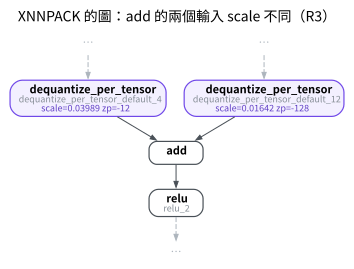

In [7]:
draw(graphs["XNNPACKQuantizer"], focus="add", hops=1, title="XNNPACK graph: the two inputs of add have different scales (R3)")

In [8]:
passed = [r for r in RULES if r not in first]
print("Rules the XNNPACK graph passes:", passed)
assert passed == ["R5", "R7"]

XNNPACK 的圖通過的規則： ['R5', 'R7']


- R5 passes: XNNPACKQuantizer also treats conv+relu and add+relu as one pattern (M04-1).
- R7 passes because `is_per_channel=True` was passed here; without it the weight would be per-tensor and this rule would be violated.

The XNNPACK graph is perfectly reasonable on a CPU (M08's XNNPACK consumes exactly this kind of graph); it just does not fit this VPU's spec. Whether the same Q/DQ graph can be deployed depends on the backend; so the backend ships its own Quantizer, and the compiler also checks on its own.

## C. What Passing the Check Buys: the Requant Factor

The accumulator of an integer conv is int32, with scale = $s_{in} \cdot s_w$; to write it back to int8 (scale = $s_{out}$) it has to be multiplied by

$$
M = \frac{s_{in} \cdot s_w}{s_{out}} \tag{1}
$$

Read the three scales of every conv/linear off the VPU graph (the weight is per-channel, so list min to max):

In [9]:
vpu = graphs["MyVPUQuantizer"]
rows, all_pow2 = [], True
for n in vpu.graph.nodes:
    if n.op != "call_function" or n.target not in (CONV2D, LINEAR):
        continue
    s_in, s_w, s_out = requant_inputs(vpu, n)
    assert s_out is not None
    m = s_in * s_w / s_out
    all_pow2 &= is_pow2(m)
    shift = (-torch.log2(m)).round().long()
    rows.append([n.name, f"2^{torch.log2(s_in).item():.0f}", f"2^{torch.log2(s_w).min():.0f} to 2^{torch.log2(s_w).max():.0f}",
                 f"2^{torch.log2(s_out).item():.0f}", f"{shift.min().item()} to {shift.max().item()}"])
table(rows, ["node", "s_in", "s_w", "s_out", "right shift (-log2 M)"])

node,s_in,s_w,s_out,右移位數（−log2 M）
conv2d,2^-5,2^-8～2^-7,2^-4,8～9
conv2d_1,2^-4,2^-9～2^-8,2^-4,8～9
conv2d_2,2^-4,2^-8～2^-7,2^-4,7～8
conv2d_3,2^-4,2^-9～2^-7,2^-4,7～9
linear,2^-5,2^-7～2^-6,2^-3,8～9


In [10]:
print("VPU graph: all M are 2^k:", all_pow2)
assert all_pow2
xnn = graphs["XNNPACKQuantizer"]
conv = next(n for n in xnn.graph.nodes if n.op == "call_function" and n.target == CONV2D)
s_in, s_w, s_out = requant_inputs(xnn, conv)
assert s_out is not None
m0 = (s_in * s_w / s_out)[0]
print(f"For comparison, XNNPACK graph: M of channel 0 of {conv.name} = {m0.item():.6g} (log2 = {torch.log2(m0).item():.3f})")

VPU 的圖：所有 M 都是 2^k： True
對照 XNNPACK 的圖：conv2d 第 0 個 channel 的 M = 0.00646425（log2 = -7.273）


All three scales on the VPU graph are decided by the Pow2 observers, so the exponent of $M$ is just the three exponents added and subtracted: shifting the accumulator right by that many bits completes the requant. The $M$ of the XNNPACK graph is not a power of 2; integer hardware generally has to do requant with a fixed-point multiply of "int32 multiplier + shift" (a common approach, not implemented in this project).

## Summary

- The checker pass is the backend's line of defense: reading only the q/dq parameters and connections on the Q/DQ graph is enough to decide whether the graph can run on this VPU.
- Every rule corresponds to a constraint in `vpu_quantizer.py`; when the quantizer fails to meet one, the pass points directly at the node.
- The benefit of power-of-2 scales becomes a concrete number: the requant of each conv is just a right-shift amount.